In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
from pathlib import Path

# Setup plotting style
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = [12, 6]

# Define paths
DATASETS_DIR = Path("../datasets")
INPUT_FILE = DATASETS_DIR / "jabref-prs.csv"

In [2]:
class PRFilter:
    def __init__(self):
        # JabRef specific issue patterns
        self.issue_patterns = [
            r'(?:fixes?|resolves?|closes?)\s+#(\d+)',
            r'(?:fixes?|resolves?|closes?)\s+issue\s+#(\d+)',
            r'(?:fixes?|resolves?|closes?)\s+jabref[/#](\d+)',
            r'https://github\.com/(?:JabRef|koppor)/jabref/issues/(\d+)',
            r'(?:^|[.\s,;])\s*#(\d+)(?=\s|$|[,.])'
        ]
        
        self.external_patterns = [
            r'https://github-redirect\.dependabot\.com/',
            r'https://github\.com/(?!JabRef/jabref|koppor/jabref)'
        ]

    def extract_issue_references(self, body: str) -> set:
        if pd.isna(body) or not str(body).strip():
            return set()
        
        body = str(body)
        issue_numbers = set()
        
        for pattern in self.issue_patterns:
            matches = re.finditer(pattern, body, re.IGNORECASE)
            for match in matches:
                issue_numbers.add(match.group(1))
        
        return issue_numbers

    def is_template_reference(self, body: str) -> bool:
        if pd.isna(body) or not str(body).strip():
            return True
        
        body = str(body)
        template_indicators = [
            r'^\s*<!--.*-->',  # Comment blocks
            r'checklist',
            r'template',
            r'placeholder',
            r'\bexample\b',
            r'\[x\]|\[ \]',  # Checkbox patterns
        ]
        
        for pattern in template_indicators:
            if re.search(pattern, body, re.IGNORECASE):
                return True
        
        return False

    def apply_filters(self, df: pd.DataFrame) -> pd.DataFrame:
        print(f"Initial count: {len(df)}")
        
        # 1. Length Metrics
        df['body_length'] = df['body'].fillna('').astype(str).str.len()
        df['word_count'] = df['body'].fillna('').astype(str).str.split().str.len()
        
        # Calculate Churn early
        df['total_churn'] = df['additions_count'].fillna(0) + df['deletions_count'].fillna(0)
        df['changed_files_count'] = df['changed_files_count'].fillna(0)
        
        df_len = df.copy()
        
        # 2. Extract issue references
        temp_references = df_len['body'].apply(self.extract_issue_references)
        
        # 3. Identify Top Frequent Issues to exclude
        all_cited_issues = [issue for issues in temp_references for issue in issues]
        if all_cited_issues:
            issue_counts = pd.Series(all_cited_issues).value_counts()
            top_5_sample_issues = set(issue_counts.head(5).index)
            print(f"Excluded Top 5 'Sample' Issues: {top_5_sample_issues}")
        else:
            top_5_sample_issues = set()
        
        def filter_and_join_issues(issues_set):
            valid_issues = issues_set - top_5_sample_issues
            return ','.join(sorted(valid_issues))

        df_len['issue_references'] = temp_references.apply(filter_and_join_issues)
        
        # 4. Strict Filter
        print("DEBUG: Executing strict filter... Churn>0 and Files>0. (Template filtering DISABLED)")
        
        # Issue Refs exists
        cond_issues = df_len['issue_references'].str.len() > 0
        
        # Valid Changes
        cond_churn = df_len['total_churn'] > 0
        cond_files = df_len['changed_files_count'] > 0
        
        # Note: cond_template removed as requested
        
        df_result = df_len[
            cond_issues & cond_churn & cond_files
        ].copy()
        
        print(f"After filtering (issues, churn > 0, files > 0): {len(df_result)}")
        
        return df_result

In [3]:
# Load and Process Data
if INPUT_FILE.exists():
    raw_df = pd.read_csv(INPUT_FILE)
    
    # Apply Pre-LLM date cutoff (<= 2022-11-30)
    raw_df['created_at'] = pd.to_datetime(raw_df['created_at'])
    cutoff_date = pd.to_datetime('2022-11-30', utc=True)
    if raw_df['created_at'].dt.tz is None:
        raw_df['created_at'] = raw_df['created_at'].dt.tz_localize('UTC')
    raw_df = raw_df[raw_df['created_at'] < cutoff_date].copy()
    print(f"Total PRs after Pre-LLM cutoff: {len(raw_df)}")
    
    processor = PRFilter()
    filtered_df = processor.apply_filters(raw_df)
else:
    print(f"File not found: {INPUT_FILE}")

Total PRs after Pre-LLM cutoff: 5625
Initial count: 5625
Excluded Top 5 'Sample' Issues: {'47', '6207', '333', '5033', '4877'}
DEBUG: Executing strict filter... Churn>0 and Files>0. (Template filtering DISABLED)
After filtering (issues, churn > 0, files > 0): 1927


In [4]:
import inspect
try:
    print(inspect.getsource(PRFilter))
except Exception as e:
    print(f"Could not get source: {e}")

Could not get source: source code not available


## Step 2: Distribution Analysis
Visualizing the distribution of key metrics (Words, Churn, Files Changed) to understand the population structure.

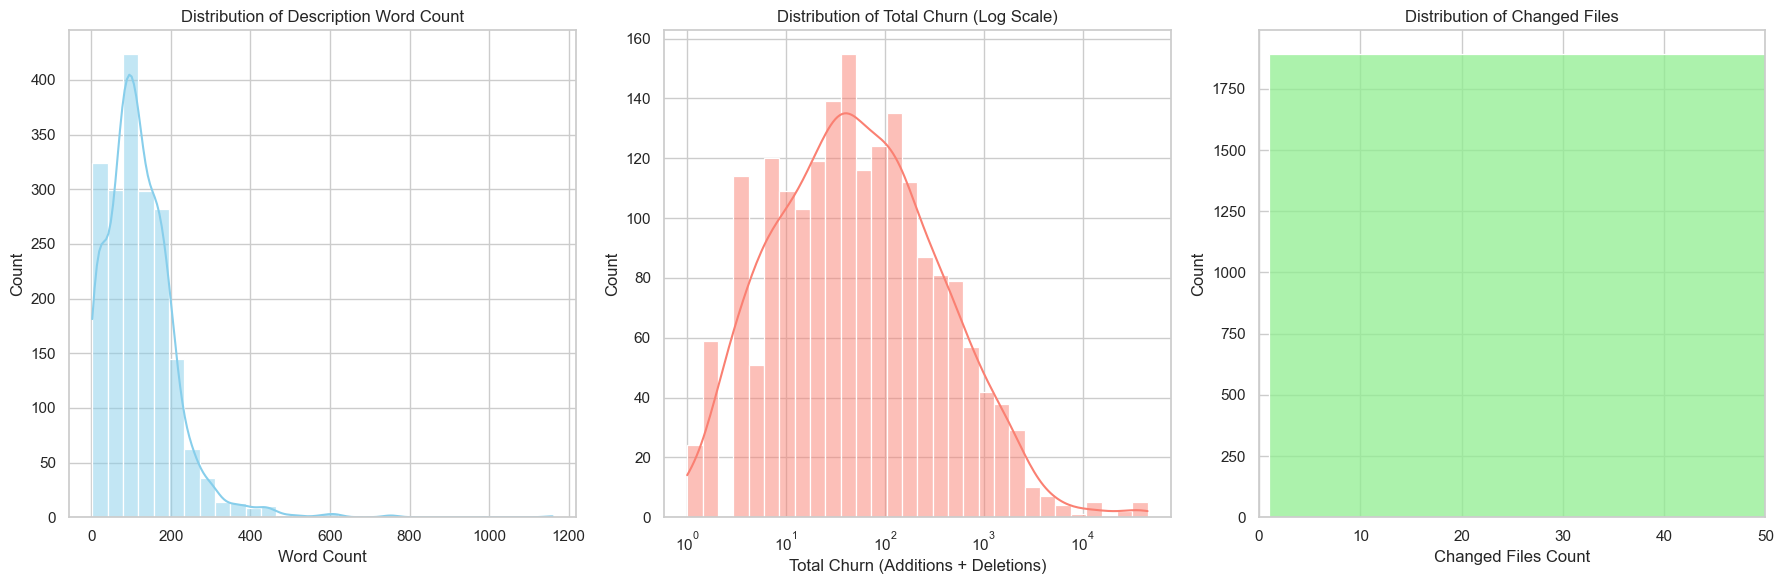

        word_count  total_churn  changed_files_count
count  1927.000000   1927.00000          1927.000000
mean    123.021796    417.52465            13.011417
std      89.992861   2447.72114            70.864084
min       2.000000      1.00000             1.000000
25%      67.000000     13.00000             2.000000
50%     110.000000     48.00000             4.000000
75%     167.000000    191.50000             9.000000
max    1160.000000  45458.00000          2244.000000


In [5]:
# Distribution Plots
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# Word Count
sns.histplot(data=filtered_df, x='word_count', bins=30, kde=True, ax=axes[0], color='skyblue')
axes[0].set_title('Distribution of Description Word Count')
axes[0].set_xlabel('Word Count')

# Total Churn (Log Scale)
sns.histplot(data=filtered_df, x='total_churn', bins=30, kde=True, ax=axes[1], color='salmon', log_scale=True)
axes[1].set_title('Distribution of Total Churn (Log Scale)')
axes[1].set_xlabel('Total Churn (Additions + Deletions)')

# Files Changed
sns.histplot(data=filtered_df, x='changed_files_count', bins=30, kde=False, ax=axes[2], color='lightgreen')
axes[2].set_title('Distribution of Changed Files')
axes[2].set_xlabel('Changed Files Count')
axes[2].set_xlim(0, 50) # Limit x-axis to see the bulk of data

plt.tight_layout()
plt.show()

# Descriptive Statistics
print(filtered_df[['word_count', 'total_churn', 'changed_files_count']].describe())

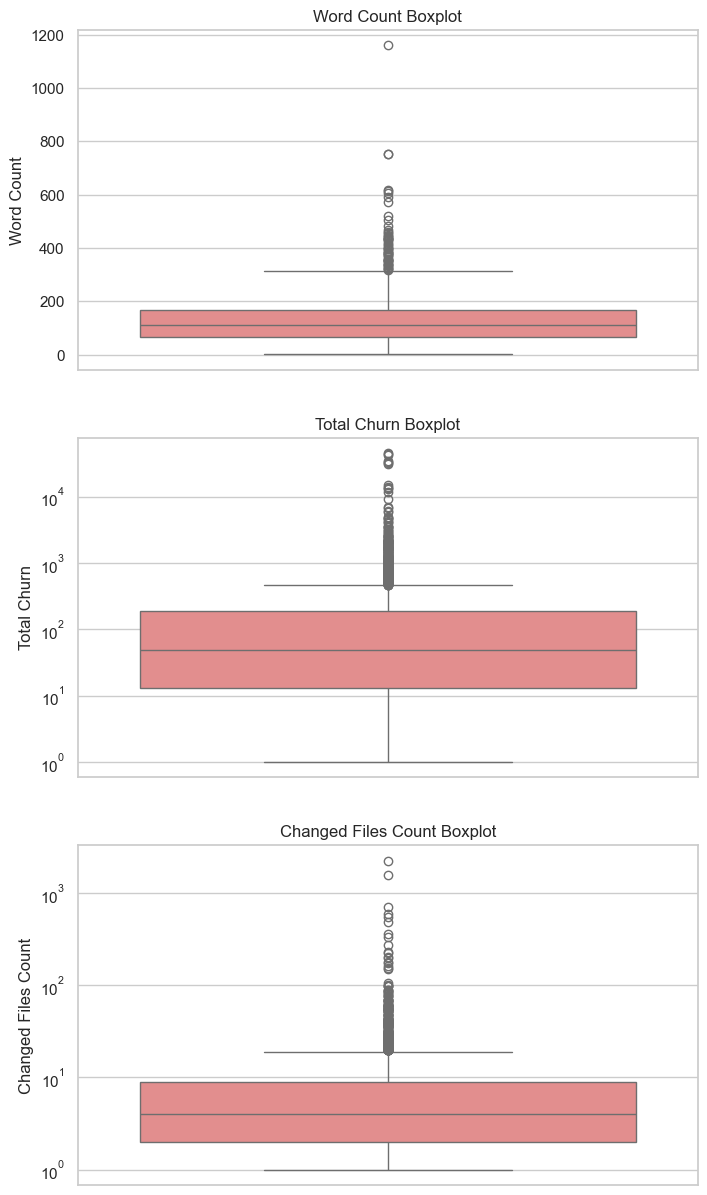

=== Outlier Analysis Report (IQR Method) ===
             Metric  Outlier Count  Percentage  Lower Bound  Upper Bound  Global Max  Outlier Min  Outlier Median  Outlier Mean  Outlier Max
         word_count             52        2.70       -83.00       317.00        1160          319          402.50        443.37         1160
        total_churn            264       13.70      -254.75       459.25       45458          469         1025.00       2552.92        45458
changed_files_count            259       13.44        -8.50        19.50        2244           20           30.00         67.97         2244


In [6]:
# Define function to detect outliers
def analyze_outliers(df, column):
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    outliers = df[(df[column] < lower_bound) | (df[column] > upper_bound)]
    return outliers, lower_bound, upper_bound

metrics = ['word_count', 'total_churn', 'changed_files_count']
outlier_stats = []

fig, axes = plt.subplots(3, 1, figsize=(8, 15))

# Increase spacing between subplots
plt.subplots_adjust(hspace=0.2)

for i, metric in enumerate(metrics):
    outliers, lb, ub = analyze_outliers(filtered_df, metric)
    
    # Store stats
    outlier_stats.append({
        'Metric': metric,
        'Outlier Count': len(outliers),
        'Percentage': (len(outliers) / len(filtered_df)) * 100,
        'Lower Bound': lb,
        'Upper Bound': ub,
        'Global Max': filtered_df[metric].max(),
        'Outlier Min': outliers[metric].min() if not outliers.empty else 0,
        'Outlier Median': outliers[metric].median() if not outliers.empty else 0,
        'Outlier Mean': outliers[metric].mean() if not outliers.empty else 0,
        'Outlier Max': outliers[metric].max() if not outliers.empty else 0
    })
    
    # Boxplot
    sns.boxplot(y=filtered_df[metric], ax=axes[i], color='lightcoral')
    axes[i].set_title(f'{" ".join([x.capitalize() for x in metric.split("_")])} Boxplot')
    axes[i].set_ylabel(metric.replace('_', ' ').title())
    if metric == 'total_churn' or metric == 'changed_files_count':
        axes[i].set_yscale('log') # Log scale for churn and file counts visualization

plt.show()

# Display Outlier Report
outlier_report = pd.DataFrame(outlier_stats)
print("=== Outlier Analysis Report (IQR Method) ===")
print(outlier_report.to_string(index=False, float_format="%.2f"))

### Outlier Analysis
We identify outliers using the Interquartile Range (IQR) method (1.5 * IQR rule) for `word_count`, `total_churn`, and `changed_files_count` to further understand the data characteristics.

## Step 3: Random Sampling
We now perform random sampling with the following parameters:
- **Confidence Level**: 95% (Z = 1.96)
- **Margin of Error**: 5% (e = 0.05)
- **Population Size (N)**: x (from previous step)

Formula:
$$ n = \frac{\frac{z^2 \cdot p(1-p)}{e^2}}{1 + \frac{z^2 \cdot p(1-p)}{e^2 \cdot N}} $$
where $p=0.5$ (maximum variability).

In [7]:
# Step 2.5: Remove Outliers
# We remove rows that are considered outliers in ANY of the key metrics to ensure a clean representative sample.

def is_outlier(df, column):
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    return (df[column] < lower_bound) | (df[column] > upper_bound)

# Identify outliers in any of the metrics
outlier_mask = (
    is_outlier(filtered_df, 'word_count') | 
    is_outlier(filtered_df, 'total_churn') | 
    is_outlier(filtered_df, 'changed_files_count')
)

clean_df = filtered_df[~outlier_mask].copy()

print(f"Original Population: {len(filtered_df)}")
print(f"Outliers Removed: {outlier_mask.sum()}")
print(f"Clean Population (N): {len(clean_df)}")


Original Population: 1927
Outliers Removed: 391
Clean Population (N): 1536


In [8]:
import math

def calculate_sample_size(population_size, confidence_level=0.95, margin_of_error=0.05):
    z_score = 1.96 # For 95% confidence
    p = 0.5 # Maximum variability
    e = margin_of_error
    
    numerator = (z_score ** 2) * p * (1 - p) / (e ** 2)
    sample_size = numerator / (1 + ((numerator - 1) / population_size))
    
    return math.ceil(sample_size)

# Calculate optimal sample size based on CLEAN population
N = len(clean_df)
required_sample_size = calculate_sample_size(N)
print(f"Clean Population Size (N): {N}")
print(f"Required Sample Size (n): {required_sample_size}")

# Perform Sampling from CLEAN dataframe
sampled_df = clean_df.sample(n=required_sample_size, random_state=23) # Fixed seed for reproducibility
print(f"Actual Sample Size: {len(sampled_df)}")

# Display Sample
sampled_df.head()


Clean Population Size (N): 1536
Required Sample Size (n): 308
Actual Sample Size: 308


,id,pull_number,title,url,state,comments_count,closed,closed_by,closed_at,merged,...,changed_files_count,additions_count,deletions_count,author_name,author_url,search_repository,body_length,word_count,total_churn,issue_references
1907,MDExOlB1bGxSZXF1ZXN0MTQ1MjYxMjkx,3274,"Terminate JavaFX thread when running with ""nog...",https://github.com/JabRef/jabref/pull/3274,MERGED,3,True,NaN,NaN,True,...,2,3,1,MrTosz,https://github.com/MrTosz,JabRef/jabref,431,62,4,3247
1660,MDExOlB1bGxSZXF1ZXN0MTEyNjM0MjEx,2688,Export single corporate author to ms office xml,https://github.com/JabRef/jabref/pull/2688,MERGED,2,True,NaN,NaN,True,...,13,244,193,Siedlerchr,https://github.com/Siedlerchr,JabRef/jabref,734,108,437,1497
3441,MDExOlB1bGxSZXF1ZXN0MzY4NjAxMTg4,5894,Fixes problems with managing external file typ...,https://github.com/JabRef/jabref/pull/5894,MERGED,16,True,NaN,NaN,True,...,5,19,14,systemoperator,https://github.com/systemoperator,JabRef/jabref,1184,178,33,5846
5510,PR_kwDOAQ0TF84-vWYa,9150,Fix missing CSS for some dialogs,https://github.com/JabRef/jabref/pull/9150,MERGED,0,True,NaN,NaN,True,...,5,10,4,HoussemNasri,https://github.com/HoussemNasri,JabRef/jabref,1433,199,14,8939
1909,MDExOlB1bGxSZXF1ZXN0MTQ1MjMyOTM5,3272,Open statistics dialog from correct thread,https://github.com/JabRef/jabref/pull/3272,MERGED,0,True,NaN,NaN,True,...,1,3,1,michaellass,https://github.com/michaellass,JabRef/jabref,758,112,4,2955


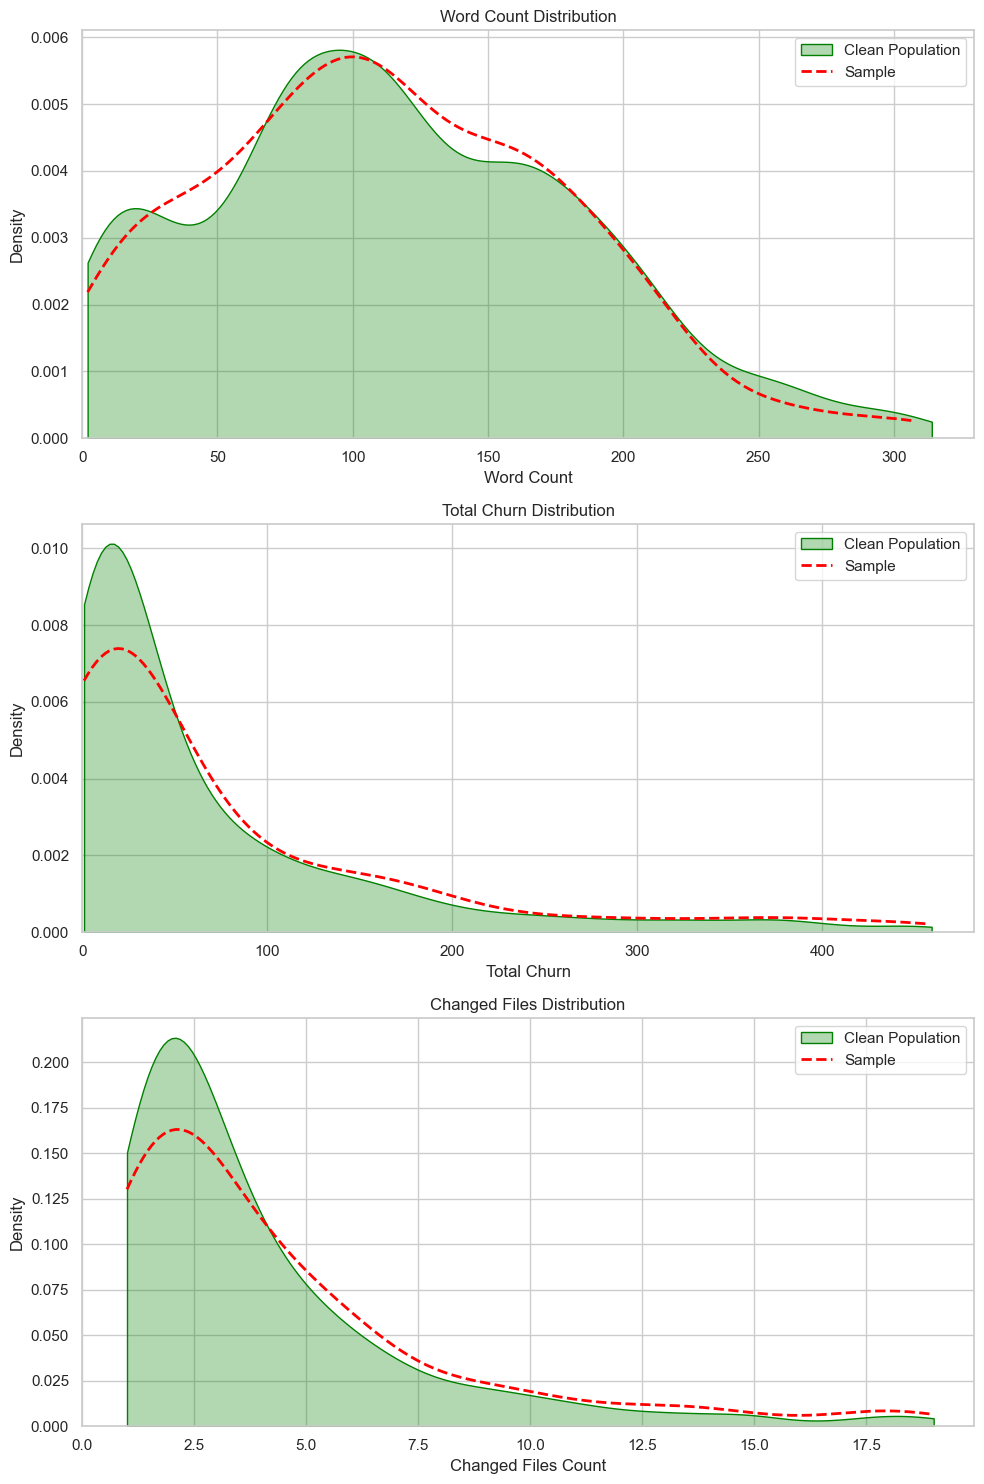

Saved sampled data to ../datasets/selected_prs_sampled.csv


In [9]:
# Verify Representation (Clean Population vs Sample)
fig, axes = plt.subplots(3, 1, figsize=(10, 15))

# Word Count Comparison
sns.kdeplot(data=clean_df, x='word_count', ax=axes[0], label='Clean Population', color='green', fill=True, alpha=0.3, cut=0)
sns.kdeplot(data=sampled_df, x='word_count', ax=axes[0], label='Sample', color='red', linestyle='--', linewidth=2, cut=0)
axes[0].set_title('Word Count Distribution')
axes[0].set_xlabel('Word Count')
axes[0].set_xlim(0, None) # Ensure x-axis starts at 0
axes[0].legend()

# Churn Comparison (Normal Scale)
sns.kdeplot(data=clean_df, x='total_churn', ax=axes[1], label='Clean Population', color='green', fill=True, alpha=0.3, cut=0)
sns.kdeplot(data=sampled_df, x='total_churn', ax=axes[1], label='Sample', color='red', linestyle='--', linewidth=2, cut=0)
axes[1].set_title('Total Churn Distribution')
axes[1].set_xlabel('Total Churn')
axes[1].set_xlim(0, None) # Ensure x-axis starts at 0
axes[1].legend()

# Changed Files Comparison
sns.kdeplot(data=clean_df, x='changed_files_count', ax=axes[2], label='Clean Population', color='green', fill=True, alpha=0.3, cut=0)
sns.kdeplot(data=sampled_df, x='changed_files_count', ax=axes[2], label='Sample', color='red', linestyle='--', linewidth=2, cut=0)
axes[2].set_title('Changed Files Distribution')
axes[2].set_xlabel('Changed Files Count')
axes[2].set_xlim(0, None) # Ensure x-axis starts at 0
axes[2].legend()

plt.tight_layout()
plt.show()

# Save the sampled data
OUTPUT_FILE = DATASETS_DIR / "selected_prs_sampled.csv"
sampled_df.to_csv(OUTPUT_FILE, index=False)
print(f"Saved sampled data to {OUTPUT_FILE}")

In [10]:
# Calculate and print stats comparison
def get_stats(df, label):
    stats = df[['word_count', 'total_churn', 'changed_files_count']].describe().loc[['mean', 'std', '50%']].T
    stats.columns = [f'{label} Mean', f'{label} Std', f'{label} Median']
    return stats

pop_stats = get_stats(clean_df, 'Pop')
sample_stats = get_stats(sampled_df, 'Sample')

comparison = pd.concat([pop_stats, sample_stats], axis=1)
print("=== Statistics Comparison (Clean Population vs Sample) ===")
print(comparison)

=== Statistics Comparison (Clean Population vs Sample) ===
                       Pop Mean    Pop Std  Pop Median  Sample Mean  \
word_count           115.210286  69.156260       108.0   113.162338   
total_churn           68.143880  91.229578        30.5    75.451299   
changed_files_count    3.990234   3.411119         3.0     4.363636   

                     Sample Std  Sample Median  
word_count            65.700482          107.5  
total_churn          101.054510           33.5  
changed_files_count    3.896575            3.0  
